# Lab: Neural Speech Representations and Classification
**Duration:** about 90 minutes, plus an optional take-home part (Part 7) for which a GPU is recommended.

In Lab 02_02 we described a voice with features designed by experts (F0, jitter, CPPS, eGeMAPS, ...).
Today we let neural networks learn the representation instead.
The data is the same as before (EmoDB, official speaker-independent split), so all results are directly comparable with the eGeMAPS baseline.

The guiding question is the one you will face in the PStA with the PARLO corpus: **with only a few hundred recordings, how do we get the most out of neural models?**
The answer in current research is almost always: use a model that was **pre-trained** on thousands of hours of speech, and use its internal representations.
The literature on speech-based dementia detection follows the same path: wav2vec 2.0, HuBERT, WavLM and Whisper embeddings, often fused with hand-crafted or linguistic features.

## Learning goals
After this lab you can
- explain why training a network from scratch on a small dataset is hard,
- explain how self-supervised speech models (wav2vec 2.0, HuBERT, WavLM) and Whisper are trained, and what their hidden layers encode,
- extract layer-wise embeddings with Hugging Face `transformers` and evaluate them with **probing classifiers**,
- explain why the best layer for paralinguistic tasks is usually in the middle of the network,
- measure how much **speaker information** is in an embedding and why that matters for clinical data,
- train a small neural classification head (layer-weighted pooling + MLP) on frozen features,
- combine hand-crafted and neural features with early and late **fusion**.

## How to work
As before: the code is mostly given, `# TODO` marks the lines that carry the key idea, and the routine is **predict → run → look → explain**.
All embeddings are cached in `~/.cache/slp_labs`, so every expensive step runs only once.
On a laptop CPU the first extraction of all embeddings takes about 5-10 minutes in total, so start Part 2 early and read the explanations while it runs.

| Part | Topic | Time |
|---|---|---|
| 0 | Setup and the baseline to beat | 5 min |
| 1 | A CNN from scratch on log-mel spectrograms | 10 min |
| 2 | Self-supervised speech models | 20 min |
| 3 | Layer-wise probing | 15 min |
| 4 | Speaker information in embeddings | 10 min |
| 5 | Neural classification heads | 15 min |
| 6 | Fusion of hand-crafted and neural features | 10 min |
| 7 | *Optional (GPU):* fine-tuning a pre-trained model | take-home |
| 8 | Summary | 5 min |

# Part 0: Setup and the Baseline to Beat (5 min)

In [1]:
# run if needed (the course uv environment already contains everything):
#!pip install audb opensmile torch transformers speechbrain librosa scikit-learn pandas matplotlib

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa
import torch
from torch import nn
from tqdm import tqdm
from IPython.display import display

from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import LeaveOneGroupOut, StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.metrics import balanced_accuracy_score, ConfusionMatrixDisplay
from sklearn.utils.class_weight import compute_class_weight

from slp_lab_utils import SR, EMOTIONS, CACHE_DIR, load_emodb, load_audio, cached, speaker_znorm

# speaker 8 has no 'disgust' utterance: sklearn warns when that fold's UAR is computed over 6 classes only
warnings.filterwarnings('ignore', message='y_pred contains classes not in y_true')

DEVICE = 'cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu'
print('device:', DEVICE)

device: mps


In [3]:
train, test = load_emodb()
y_train = train.emotion.to_numpy().astype(str)
y_test = test.emotion.to_numpy().astype(str)
spk_train = train.speaker.to_numpy()
speaker_cv = LeaveOneGroupOut()   # 6 folds: train on 5 speakers, validate on the 6th

We collect every system in a `results` table.
For model selection we only look at the **speaker-independent cross-validation UAR** on the training set.
We also compute the test UAR of every system, but we only look at it in the summary (Part 8), to see how well cross-validation predicted the test result.
In a real study (your PStA!) you would pick **one** system by cross-validation and report only its test score.

In [4]:
results = {}

def evaluate(name, model, X_train, X_test):
    """Speaker-independent CV on train, then fit on all of train and predict the test set (stored, not printed)."""
    cv = cross_val_score(model, X_train, y_train, groups=spk_train, cv=speaker_cv, scoring='balanced_accuracy')
    test_pred = clone(model).fit(X_train, y_train).predict(X_test)
    results[name] = {'cv_uar': cv.mean(), 'cv_std': cv.std(), 'test_uar': balanced_accuracy_score(y_test, test_pred)}
    print(f'{name:45s} CV UAR = {cv.mean():.3f} ± {cv.std():.3f}')
    return test_pred

The eGeMAPS features from Lab 02_02 are loaded from the cache (or extracted again, which takes about 20 s).

In [5]:
import opensmile

egemaps = opensmile.Smile(feature_set=opensmile.FeatureSet.eGeMAPSv02, feature_level=opensmile.FeatureLevel.Functionals)
egemaps_train = cached('emodb_egemaps_train', lambda: egemaps.process_files(train.file).reset_index(drop=True))
egemaps_test = cached('emodb_egemaps_test', lambda: egemaps.process_files(test.file).reset_index(drop=True))

svm = make_pipeline(SimpleImputer(), StandardScaler(), SVC(C=1, gamma=0.01, class_weight='balanced'))
evaluate('eGeMAPS + SVM (Lab 02_02)', svm, egemaps_train, egemaps_test);

eGeMAPS + SVM (Lab 02_02)                     CV UAR = 0.629 ± 0.118


# Part 1: A CNN from Scratch on Log-Mel Spectrograms (10 min)

The most direct neural approach: feed the **log-mel spectrogram** (Lecture 02) into a convolutional neural network (CNN) and let it learn the features.
- Every utterance becomes an image of 64 mel bands × 400 frames (10 ms hop, so 4 s; longer utterances are cut, shorter ones padded).
- Four convolution blocks (3×3 convolution → batch normalisation → ReLU → 2×2 max pooling) learn local time-frequency patterns, such as harmonics, formant movements and onsets.
- **Global average pooling** averages the last feature maps over frequency and time.
  This gives one vector per utterance regardless of where in the utterance a pattern occurred.
- A linear layer maps this vector to the 7 classes.
- The loss is **class-weighted cross-entropy**: errors on rare classes (disgust) cost more, the neural counterpart of `class_weight='balanced'`.

Predict before you run: the network has about 70 000 parameters, and we have 304 training utterances. How well will it do compared with eGeMAPS?

In [6]:
N_FRAMES = 400

def logmel(path):
    S = librosa.feature.melspectrogram(y=load_audio(path), sr=SR, n_fft=400, hop_length=160, n_mels=64)
    S = librosa.power_to_db(S, ref=np.max, top_db=80)
    return librosa.util.fix_length(S, size=N_FRAMES, axis=1, constant_values=-80)   # cut or pad to 4 s

mel_train = cached('emodb_logmel_train', lambda: np.stack([logmel(f) for f in train.file]))
mel_test = cached('emodb_logmel_test', lambda: np.stack([logmel(f) for f in test.file]))
mu, sigma = mel_train.mean(), mel_train.std()          # normalise with training statistics only
print(mel_train.shape)

(304, 64, 400)


In [7]:
class SmallCNN(nn.Module):
    def __init__(self, n_classes=len(EMOTIONS)):
        super().__init__()
        def block(c_in, c_out):
            return nn.Sequential(nn.Conv2d(c_in, c_out, 3, padding=1), nn.BatchNorm2d(c_out), nn.ReLU(), nn.MaxPool2d(2))
        self.features = nn.Sequential(block(1, 16), block(16, 32), block(32, 64), block(64, 64))
        self.classifier = nn.Sequential(nn.Dropout(0.3), nn.Linear(64, n_classes))

    def forward(self, x):            # x: (batch, 1, mel bands, frames)
        x = self.features(x)         # (batch, 64, mel bands / 16, frames / 16)
        x = x.mean(dim=(2, 3))
        return self.classifier(x)    # (batch, n_classes) logits


def train_cnn(seed, epochs=30, batch_size=16):
    torch.manual_seed(seed)
    model = SmallCNN().to(DEVICE)
    X = torch.tensor((mel_train - mu) / sigma, dtype=torch.float32)[:, None]
    y = torch.tensor(pd.Categorical(y_train, categories=EMOTIONS).codes, dtype=torch.long)
    weights = compute_class_weight('balanced', classes=np.arange(len(EMOTIONS)), y=y.numpy())
    loss_fn = nn.CrossEntropyLoss(weight=torch.tensor(weights, dtype=torch.float32).to(DEVICE))
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    for epoch in range(epochs):
        model.train()
        for idx in torch.randperm(len(X)).split(batch_size):
            optimizer.zero_grad()
            loss = loss_fn(model(X[idx].to(DEVICE)), y[idx].to(DEVICE))
            loss.backward()
            optimizer.step()
    return model


@torch.no_grad()
def predict_cnn(model, mel):
    model.eval()
    X = torch.tensor((mel - mu) / sigma, dtype=torch.float32)[:, None].to(DEVICE)
    return np.array(EMOTIONS)[model(X).argmax(1).cpu().numpy()]

print('number of parameters:', sum(p.numel() for p in SmallCNN().parameters()))

number of parameters: 61031


Leave-one-speaker-out cross-validation of a CNN means training 6 networks per setting, which is too slow for a lab.
We therefore fix all hyperparameters *in advance* (no tuning!) and train the network on the full training set with three different random seeds.

In [8]:
cnn_uars = []
for seed in range(3):
    model = train_cnn(seed)
    cnn_uars.append(balanced_accuracy_score(y_test, predict_cnn(model, mel_test)))
    print(f'seed {seed}: test UAR = {cnn_uars[-1]:.3f}')
results['log-mel CNN from scratch'] = {'cv_uar': np.nan, 'cv_std': np.nan, 'test_uar': np.mean(cnn_uars)}
print(f'mean over seeds: {np.mean(cnn_uars):.3f} ± {np.std(cnn_uars):.3f}')

seed 0: test UAR = 0.595


seed 1: test UAR = 0.718


seed 2: test UAR = 0.335
mean over seeds: 0.549 ± 0.160


**Questions**
1. How does the CNN compare with eGeMAPS? How much do the results vary between seeds, and what does that tell you about reporting a single run?
2. Why does global average pooling make sense for emotion (and for dementia), but not for speech recognition?
3. Name two things that would probably help the CNN, and explain why they do not change the fundamental problem.

**Solution:**
1. On average the CNN is below eGeMAPS (about 0.55 test UAR), and the seeds differ dramatically (in our run between about 0.34 and 0.72).
   With 304 utterances the network sees too few examples to learn robust features, so the result depends heavily on the random initialisation and data order.
   A single lucky run would have looked better than eGeMAPS: always report mean and spread over several seeds.
2. Emotion (or a disease) is a property of the *whole* utterance, so it is fine to average the evidence over time.
   Speech recognition needs the *order* of the sounds, which average pooling destroys.
3. Data augmentation (noise, speed and pitch perturbation, SpecAugment), and a smaller or more regularised network.
   They reduce overfitting, but the network still has to learn everything about speech from a few hundred examples.
   The real solution is to start from a model that has already learned about speech from a lot of other data: pre-training (Part 2).

# Part 2: Self-supervised Speech Models (20 min)

## Learning from unlabelled speech
Labelled data is expensive, unlabelled speech is almost free.
**Self-supervised learning (SSL)** trains a network on a task that needs no labels, and the internal representations it learns turn out to be useful for many other tasks.
All three SSL models we use share the same architecture:

1. A **CNN feature encoder** turns the raw waveform (16 kHz) into one vector every **20 ms** ("frames").
2. A **Transformer** with 12 layers (base models) contextualises these frames: every output frame "sees" the whole utterance through self-attention.
3. During pre-training, some frames are **masked**, and the model has to infer what was there from the context, similar to masked language modelling in BERT.

They differ in *what* has to be predicted for the masked frames:

| Model | Pre-training target | Data |
|---|---|---|
| **wav2vec 2.0** (Baevski et al., 2020) | pick the true (quantised) frame among distractors, a **contrastive** task | 960 h LibriSpeech (read English audiobooks) |
| **HuBERT** (Hsu et al., 2021) | predict the **cluster ID** of the masked frame; the clusters come from k-means on MFCCs (1st iteration) or on HuBERT's own features (2nd iteration) | 960 h LibriSpeech |
| **WavLM** (Chen et al., 2022) | like HuBERT, but the input is artificially **overlapped with other speakers and noise**, and the model must predict the targets of the main speaker | 94 000 h (Libri-Light, GigaSpeech, VoxPopuli) |

Then there is a model trained with labels:

| Model | Training | Data |
|---|---|---|
| **Whisper** (Radford et al., 2023) | **supervised**: an encoder-decoder Transformer that transcribes and translates speech; we only use the **encoder** | 680 000 h of weakly labelled web audio, 97 languages |

Whisper's encoder works on 80 log-mel bands (not on the raw waveform), pads every input to 30 s, and produces one frame every 20 ms.
We use `whisper-base` (6 encoder layers), the others are "base" models with 12 layers.

Note that the SSL models were pre-trained on **English** read speech and we use them on German emotional speech.
That works because the lower and middle layers mostly encode acoustic and phonetic properties, which are largely language-independent.

## What do the layers encode?
A Transformer layer outputs one 768-dimensional vector per 20 ms frame.
To get one vector per utterance we **mean-pool over time** (as global average pooling in the CNN).
We do this for the output of the CNN encoder (layer 0) and for every Transformer layer, so every utterance becomes a matrix of shape (layers, 768).
Which layer is best for emotion is an empirical question, and Part 3 answers it.

## Task 2.1: Extract layer-wise embeddings
Complete the pooling line.
`hidden` is a tuple with one tensor of shape `(1, frames, dim)` per layer.

In [9]:
from transformers import AutoFeatureExtractor, AutoModel, WhisperFeatureExtractor, WhisperModel

@torch.inference_mode()
def ssl_embeddings(model_name, files):
    """Mean-pooled hidden states of all layers, array of shape (n_files, n_layers + 1, dim)."""
    if 'whisper' in model_name:
        extractor = WhisperFeatureExtractor.from_pretrained(model_name)
        model = WhisperModel.from_pretrained(model_name).encoder
    else:
        extractor = AutoFeatureExtractor.from_pretrained(model_name)
        model = AutoModel.from_pretrained(model_name)
    model = model.to(DEVICE).eval()

    out = []
    for f in tqdm(files, desc=model_name):
        y = load_audio(f)
        inputs = extractor(y, sampling_rate=SR, return_tensors='pt').to(DEVICE)
        hidden = model(**inputs, output_hidden_states=True).hidden_states
        if 'whisper' in model_name:
            n = int(np.ceil(len(y) / SR * 50))   # Whisper pads to 30 s: keep only the frames (50 per second) that contain audio
            hidden = [h[:, :n] for h in hidden]
        pooled = torch.stack([h[0].mean(dim=0) for h in hidden])
        out.append(pooled.cpu().numpy())
    return np.stack(out)


SSL_MODELS = {
    'wav2vec2': 'facebook/wav2vec2-base',
    'HuBERT': 'facebook/hubert-base-ls960',
    'WavLM': 'microsoft/wavlm-base-plus',
    'Whisper': 'openai/whisper-base',
}
embeddings = {}
for key, name in SSL_MODELS.items():
    embeddings[key] = (cached(f'emodb_{key}_train', lambda: ssl_embeddings(name, train.file)),
                       cached(f'emodb_{key}_test', lambda: ssl_embeddings(name, test.file)))
    print(f'{key:10s} train {embeddings[key][0].shape}   test {embeddings[key][1].shape}')

/Users/bayerl/src/lectures/SpeechAndLanguageProcessing_Master/WS2627/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1020 14:22:21.887000 35178 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


wav2vec2   train (304, 13, 768)   test (231, 13, 768)
HuBERT     train (304, 13, 768)   test (231, 13, 768)
WavLM      train (304, 13, 768)   test (231, 13, 768)
Whisper    train (304, 7, 512)   test (231, 7, 512)


**Questions**
1. Why do the SSL models produce 13 "layers" and Whisper 7?
2. Why must we cut the padding off before pooling Whisper's frames? What would happen otherwise?
3. Mean pooling throws away the temporal structure. Which information that might be relevant for dementia could get lost? Which other pooling would you try?

**Solution:**
1. Layer 0 is the input to the Transformer (the output of the CNN feature encoder, or Whisper's convolutional stem), followed by 12 (base SSL models) or 6 (Whisper base) Transformer layers.
2. Whisper pads every input to 30 s.
   For a 2 s utterance, more than 90 % of the frames would encode padding, and the mean would mostly describe "silence at the end", with a strong dependence on the utterance length.
3. Mean pooling keeps the average properties, but loses where and how often something happens: the number and position of pauses, a slowing-down towards the end, the variability over time.
   Alternatives: mean **and** standard deviation (statistics pooling), attention pooling (a learned weighting of frames), or sequence models on the frames.

# Part 3: Layer-wise Probing (15 min)

A **probe** is a deliberately simple classifier (here: logistic regression) trained on a frozen representation.
If a linear model can read the emotion out of a layer, then this layer encodes the emotion in an easily accessible way.
We train one probe per layer and per model, always with the speaker-independent cross-validation.
This takes about a minute.

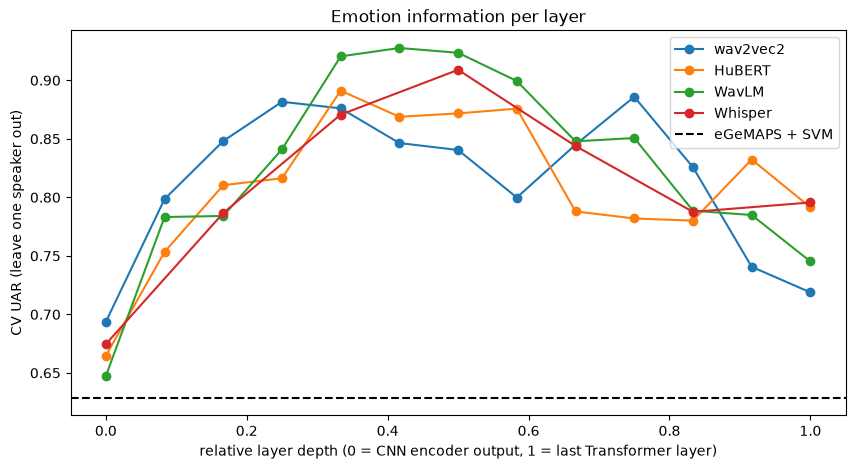

In [10]:
def probe():
    return make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=2000, class_weight='balanced'))

layer_uar = {}
for key, (H_train, _) in embeddings.items():
    layer_uar[key] = [
        cross_val_score(probe(), H_train[:, layer], y_train, groups=spk_train, cv=speaker_cv, scoring='balanced_accuracy').mean()
        for layer in range(H_train.shape[1])
    ]

fig, ax = plt.subplots(figsize=(10, 5))
for key, uars in layer_uar.items():
    depth = np.linspace(0, 1, len(uars))      # relative depth, so that 6 and 12 layer models can be compared
    ax.plot(depth, uars, 'o-', label=key)
ax.axhline(results['eGeMAPS + SVM (Lab 02_02)']['cv_uar'], color='k', ls='--', label='eGeMAPS + SVM')
ax.set_xlabel('relative layer depth (0 = CNN encoder output, 1 = last Transformer layer)')
ax.set_ylabel('CV UAR (leave one speaker out)')
ax.legend()
ax.set_title('Emotion information per layer');

We choose the best model and layer by cross-validation and add it to the results.

In [11]:
best_key, best_layer = max(((k, l) for k in layer_uar for l in range(len(layer_uar[k]))), key=lambda kl: layer_uar[kl[0]][kl[1]])
print('best by CV:', best_key, 'layer', best_layer)

X_ssl_train = embeddings[best_key][0][:, best_layer]
X_ssl_test = embeddings[best_key][1][:, best_layer]
evaluate(f'{best_key} layer {best_layer} + logistic regression', probe(), X_ssl_train, X_ssl_test)
evaluate(f'{best_key} last layer + logistic regression', probe(), embeddings[best_key][0][:, -1], embeddings[best_key][1][:, -1]);

best by CV: WavLM layer 5
WavLM layer 5 + logistic regression           CV UAR = 0.928 ± 0.041


WavLM last layer + logistic regression        CV UAR = 0.745 ± 0.123


**Questions**
1. How do the best layers compare with the eGeMAPS baseline? And with the CNN from scratch?
2. Where in the network is the emotion information strongest? Why is the **last** layer not the best, given how the models were pre-trained?
3. Compare WavLM with wav2vec 2.0 and HuBERT. Which difference in pre-training could explain the ranking?
4. Whisper was trained to transcribe, which seems unrelated to emotion. Why does its encoder still work well?
5. We chose the layer by looking at 4 × 13 cross-validation scores. Why is the best CV score now slightly optimistic, and what protects us from fooling ourselves?

**Solution:**
1. The best SSL layers reach about 0.9 UAR in cross-validation (WavLM layer 5: about 0.93), far above eGeMAPS (about 0.63) and the CNN from scratch.
   Pre-training on thousands of hours of speech gives representations that a linear classifier can use with only 304 examples.
2. In the middle (relative depth 0.3-0.6); wav2vec 2.0 has a second, smaller peak further up.
   The lower layers are close to the acoustics, the upper layers specialise in the pre-training target: predicting phonetic units (HuBERT, WavLM) or quantised frames (wav2vec 2.0).
   Phonetic content is *what* is said, which is irrelevant for emotion, so information about *how* it is said is partly discarded towards the top.
3. WavLM is usually best: it saw 100 times more and more varied data, and its denoising task with overlapping speakers forces it to model speaker and voice properties explicitly.
   That is why WavLM leads the paralinguistic and speaker tasks of the SUPERB benchmark.
4. To transcribe robustly across speakers, accents, noise and speaking styles, the encoder has to model all of these acoustic factors, especially in its lower and middle layers.
   It was also trained on very varied real-world audio, including emotional speech.
5. Selecting the maximum of many noisy estimates favours configurations that were lucky on these 6 speakers (a "winner's curse").
   The untouched test set protects us: as long as we look at it only once, it gives an unbiased estimate of the selected system.

# Part 4: Speaker Information in Embeddings (10 min)

Embeddings encode much more than the target: speaker identity, gender, age, microphone and room.
In emotion recognition that is a nuisance.
In the PARLO corpus it is a **risk**: if a representation encodes the speaker and the recording site very well, a classifier can learn "who" or "where" instead of "how healthy".

**Speaker embeddings** are trained to do exactly that.
**ECAPA-TDNN** (Desplanques et al., 2020) is a CNN with channel attention and attentive statistics pooling, trained to classify 7000 speakers of VoxCeleb.
The 192-dimensional output (an "x-vector") is used for speaker verification.

## Task 4.1: How much speaker and how much emotion is in a representation?
We probe for two targets:
- **emotion**, with the speaker-independent cross-validation as before,
- **speaker identity** (6 training speakers), with a stratified 5-fold cross-validation (it has to see every speaker in training).

In [12]:
from speechbrain.inference.speaker import EncoderClassifier

ecapa = EncoderClassifier.from_hparams('speechbrain/spkrec-ecapa-voxceleb', savedir=str(CACHE_DIR / 'ecapa'),
                                       run_opts={'device': DEVICE})

@torch.inference_mode()
def ecapa_embeddings(files):
    return np.stack([ecapa.encode_batch(torch.tensor(load_audio(f))[None]).squeeze().cpu().numpy() for f in tqdm(files)])

ecapa_train = cached('emodb_ecapa_train', lambda: ecapa_embeddings(train.file))
ecapa_test = cached('emodb_ecapa_test', lambda: ecapa_embeddings(test.file))

In [13]:
speaker_folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

def speaker_and_emotion(X):
    spk = cross_val_score(probe(), X, spk_train, cv=speaker_folds, scoring='balanced_accuracy').mean()
    emo = cross_val_score(probe(), X, y_train, groups=spk_train, cv=speaker_cv, scoring='balanced_accuracy').mean()
    return spk, emo

H_wavlm = embeddings['WavLM'][0]
rows = {'ECAPA (speaker embedding)': speaker_and_emotion(ecapa_train),
        'eGeMAPS': speaker_and_emotion(SimpleImputer().fit_transform(egemaps_train))}
for layer in range(H_wavlm.shape[1]):
    rows[f'WavLM layer {layer}'] = speaker_and_emotion(H_wavlm[:, layer])
probe_table = pd.DataFrame(rows, index=['speaker ID (UAR)', 'emotion (UAR)']).T.round(3)
display(probe_table)

evaluate('ECAPA + logistic regression', probe(), ecapa_train, ecapa_test);

,speaker ID (UAR),emotion (UAR)
ECAPA (speaker embedding),1.000,0.624
eGeMAPS,0.758,0.651
WavLM layer 0,0.960,0.647
WavLM layer 1,1.000,0.783
WavLM layer 2,1.000,0.784
WavLM layer 3,1.000,0.841
WavLM layer 4,1.000,0.920
WavLM layer 5,0.997,0.928
WavLM layer 6,0.974,0.924
WavLM layer 7,0.950,0.899


ECAPA + logistic regression                   CV UAR = 0.624 ± 0.070


## Task 4.2: Remove the speaker
As in Lab 02_02, we z-normalise every dimension per speaker and check what happens to emotion recognition with the best SSL layer.

In [14]:
X_ssl_train_norm = speaker_znorm(X_ssl_train, spk_train)
X_ssl_test_norm = speaker_znorm(X_ssl_test, test.speaker)
evaluate(f'{best_key} layer {best_layer}, speaker-normalised', probe(), X_ssl_train_norm, X_ssl_test_norm);

WavLM layer 5, speaker-normalised             CV UAR = 0.949 ± 0.034


**Questions**
1. Which representation identifies the speaker best, and which recognises emotion best? Are the two related?
2. How does speaker information change across the WavLM layers?
3. ECAPA was trained to *ignore* everything except the speaker. Why does it still recognise emotions clearly above chance?
4. Does speaker normalisation help the SSL embeddings as much as it helped eGeMAPS in Lab 02_02? Why might that be?
5. Transfer: in the PARLO corpus each speaker has one diagnosis and was recorded at one of 9 sites. Describe how a classifier could get a good score for the wrong reasons, and an experiment that would reveal it.

**Solution:**
1. ECAPA and the lower and middle WavLM layers identify the 6 speakers perfectly, eGeMAPS reaches about 0.76.
   Emotion is best in the middle WavLM layers (about 0.93), while ECAPA only reaches about 0.62, no better than eGeMAPS.
   Speaker and emotion information are different things: a representation can be perfect for one and mediocre for the other.
2. Speaker identity is perfect in layers 1-5 and drops to about 0.86-0.89 in the upper layers, where the representation becomes more phonetic (*what* is said instead of *who* says it).
   The middle layers are good at both, which is exactly why they are a risk for confounding.
3. Speaker embeddings encode the *voice* in a recording, and emotion changes the voice (F0, voice quality, loudness), so some of it leaks into the embedding.
   It works the other way round as well: emotion, health and recording conditions are known nuisance factors for speaker verification.
4. Yes, it still helps (about 0.93 → 0.95 in CV), although the SSL layer is already strong.
   The best layer encodes the speaker perfectly (Task 4.1), and removing the speaker offsets makes the emotion differences easier to separate.
   Remember the condition from Lab 02_02: this only works because every EmoDB speaker produces all emotions.
5. If, for example, more DEM patients were recorded at one site, the classifier can learn the room acoustics or the examiner's voice of that site.
   Within the data the score looks good, but on a new clinic it fails.
   Experiments: leave-one-site-out cross-validation, probing the embeddings for the site ID, and checking whether the predictions correlate with site, age or gender within each diagnostic group.

# Part 5: Neural Classification Heads (15 min)

So far the classifier on top of the embeddings was linear.
Now we train small neural networks on the **frozen** embeddings.
This is cheap (seconds on a CPU) and is the standard setup of the SUPERB benchmark for comparing speech models.

## 5a: An MLP on the best layer
`sklearn.neural_network.MLPClassifier` is a multilayer perceptron: one hidden layer with ReLU, trained with Adam and L2 regularisation (`alpha`).

In [15]:
mlp = make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(256,), alpha=1.0, max_iter=500, random_state=0))
evaluate(f'{best_key} layer {best_layer} + MLP', mlp, X_ssl_train, X_ssl_test);

WavLM layer 5 + MLP                           CV UAR = 0.909 ± 0.049


## 5b: Learn which layers to use
Instead of choosing one layer by hand, we let the network learn a **weighted sum of all layers** (as in SUPERB and in Hugging Face's `use_weighted_layer_sum`):
$$\mathbf{x} = \sum_{l=0}^{L} w_l \, \mathbf{h}_l, \qquad w_l = \frac{e^{a_l}}{\sum_k e^{a_k}}$$
The $a_l$ are trainable parameters, and the softmax makes the weights positive and sum to 1.
The weighted sum is followed by an MLP.
The 13 layer logits get their own, larger learning rate and no weight decay: they are only 13 numbers, and with the small learning rate of the MLP they would hardly move away from uniform weights.

We wrap the PyTorch model as a scikit-learn estimator (`fit`, `predict`, `predict_proba`).
That way we can reuse `cross_val_score`, `LeaveOneGroupOut` and our `evaluate` function unchanged.

WavLM all layers + layer-weighted MLP         CV UAR = 0.887 ± 0.075


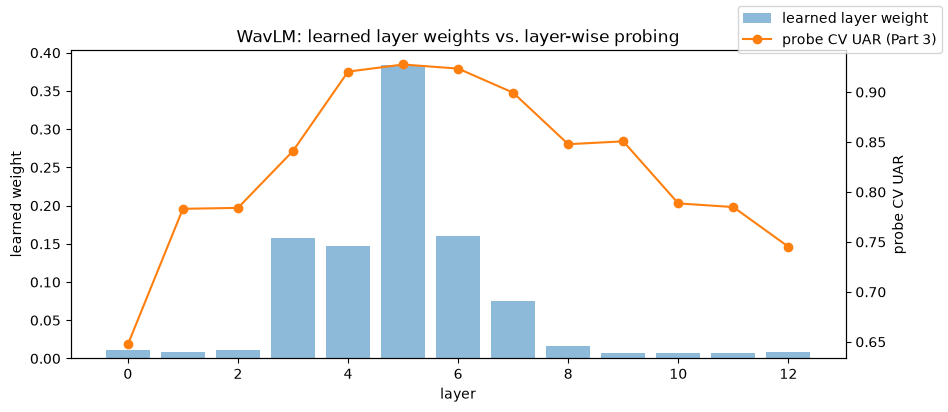

In [16]:
class LayerWeightedMLP(ClassifierMixin, BaseEstimator):
    """Softmax-weighted sum over layers + MLP, trained full-batch with class-weighted cross-entropy.

    X has shape (n_samples, n_layers, dim).
    """

    def __init__(self, hidden=256, dropout=0.3, lr=1e-3, layer_lr=5e-2, weight_decay=1e-2, epochs=150, seed=0):
        self.hidden, self.dropout, self.lr, self.layer_lr = hidden, dropout, lr, layer_lr
        self.weight_decay, self.epochs, self.seed = weight_decay, epochs, seed

    def _forward(self, X):
        w = torch.softmax(self.layer_logits_, dim=0)
        x = (w[None, :, None] * X).sum(dim=1)
        return self.mlp_(x)

    def fit(self, X, y):
        torch.manual_seed(self.seed)
        self.classes_, y_idx = np.unique(y, return_inverse=True)
        X = torch.tensor(np.asarray(X), dtype=torch.float32)
        self.mean_, self.std_ = X.mean(0), X.std(0) + 1e-5            # standardise every layer and dimension
        X = (X - self.mean_) / self.std_
        self.layer_logits_ = nn.Parameter(torch.zeros(X.shape[1]))     # start with equal weights for all layers
        self.mlp_ = nn.Sequential(nn.Dropout(self.dropout), nn.Linear(X.shape[2], self.hidden), nn.ReLU(),
                                  nn.Dropout(self.dropout), nn.Linear(self.hidden, len(self.classes_)))
        weights = compute_class_weight('balanced', classes=self.classes_, y=y)
        loss_fn = nn.CrossEntropyLoss(weight=torch.tensor(weights, dtype=torch.float32))
        optimizer = torch.optim.AdamW([
            {'params': [self.layer_logits_], 'lr': self.layer_lr, 'weight_decay': 0.0},
            {'params': self.mlp_.parameters()},
        ], lr=self.lr, weight_decay=self.weight_decay)
        target = torch.tensor(y_idx)
        self.mlp_.train()
        for _ in range(self.epochs):                                   # full batch: 304 utterances fit into memory
            optimizer.zero_grad()
            loss = loss_fn(self._forward(X), target)
            loss.backward()
            optimizer.step()
        return self

    @torch.no_grad()
    def predict_proba(self, X):
        self.mlp_.eval()
        X = (torch.tensor(np.asarray(X), dtype=torch.float32) - self.mean_) / self.std_
        return torch.softmax(self._forward(X), dim=1).numpy()

    def predict(self, X):
        return self.classes_[self.predict_proba(X).argmax(1)]


H_train, H_test = embeddings[best_key]
evaluate(f'{best_key} all layers + layer-weighted MLP', LayerWeightedMLP(), H_train, H_test)

head = LayerWeightedMLP().fit(H_train, y_train)
fig, ax1 = plt.subplots(figsize=(10, 4))
ax1.bar(range(H_train.shape[1]), torch.softmax(head.layer_logits_, 0).detach().numpy(), alpha=0.5, label='learned layer weight')
ax1.set_xlabel('layer'); ax1.set_ylabel('learned weight')
ax2 = ax1.twinx()
ax2.plot(layer_uar[best_key], 'o-', color='C1', label='probe CV UAR (Part 3)')
ax2.set_ylabel('probe CV UAR')
fig.legend(loc='upper right')
ax1.set_title(f'{best_key}: learned layer weights vs. layer-wise probing');

**Questions**
1. Does the MLP beat the linear probe? Is that what you expected with 304 training samples?
2. Which layers get the highest learned weights? Do they agree with the probing curve from Part 3?
3. The layer-weighted head has about 200 000 parameters, the CNN from Part 1 only 70 000. Why does the head nevertheless work so much better?

**Solution:**
1. The MLP is about as good as the linear probe, or slightly worse (about 0.91 vs. 0.93).
   The embeddings are already linearly separable to a large degree, and with 304 samples the extra capacity of the MLP mainly adds variance.
2. The weights peak at the middle layers (in our run layer 5 gets about 0.4, layers 3-6 most of the rest), which agrees well with the probing curve: the head found the best layers by itself, from the training data only.
   Its CV UAR (about 0.89) is still slightly below the best single layer, because it has to learn more parameters from the same 304 utterances.
   Choosing the layer by probing, on the other hand, needed 13 separate cross-validations, and that selection is itself slightly optimistic.
3. The representation is already good: the head only has to learn a simple mapping from emotion-relevant features to classes.
   The CNN has to learn the features *and* the mapping from the same 304 examples.

# Part 6: Fusion of Hand-crafted and Neural Features (10 min)

The PStA requires two unimodal baselines and a **fusion** model.
The two standard ways to fuse, shown here with two acoustic representations (eGeMAPS and the best SSL layer):
- **Early fusion** (feature level): concatenate the feature vectors and train one classifier.
  Simple, but the larger block can dominate, and the dimensionality grows.
- **Late fusion** (decision level): train one classifier per representation and combine their **predicted probabilities**, for example by averaging.
  Robust and modular: each model can be tuned separately, and a missing modality is easy to handle.

In the PStA, the same ideas apply to audio + text (e.g. WavLM embeddings + features from an ASR transcript).

We use logistic regression for both representations, because it gives well-calibrated probabilities.

In [17]:
def lr():
    return make_pipeline(SimpleImputer(), StandardScaler(), LogisticRegression(C=0.1, max_iter=2000, class_weight='balanced'))

# early fusion: concatenate
X_early_train = np.hstack([egemaps_train, X_ssl_train])
X_early_test = np.hstack([egemaps_test, X_ssl_test])
evaluate(f'early fusion: eGeMAPS + {best_key} layer {best_layer}', lr(), X_early_train, X_early_test)

# late fusion: average the probabilities of two separately trained models
def late_fusion_proba(Xa_train, Xb_train, Xa_test=None, Xb_test=None):
    """Out-of-fold (speaker CV) probabilities on train, or test probabilities if test features are given."""
    if Xa_test is None:
        p_a = cross_val_predict(lr(), Xa_train, y_train, groups=spk_train, cv=speaker_cv, method='predict_proba')
        p_b = cross_val_predict(lr(), Xb_train, y_train, groups=spk_train, cv=speaker_cv, method='predict_proba')
    else:
        p_a = lr().fit(Xa_train, y_train).predict_proba(Xa_test)
        p_b = lr().fit(Xb_train, y_train).predict_proba(Xb_test)
    p_fused = (p_a + p_b) / 2
    return p_fused

classes = np.unique(y_train)                       # column order of predict_proba
pred_cv = classes[late_fusion_proba(egemaps_train, X_ssl_train).argmax(1)]
fold_uar = [balanced_accuracy_score(y_train[spk_train == s], pred_cv[spk_train == s]) for s in np.unique(spk_train)]
pred_test = classes[late_fusion_proba(egemaps_train, X_ssl_train, egemaps_test, X_ssl_test).argmax(1)]
name = f'late fusion: eGeMAPS + {best_key} layer {best_layer}'
results[name] = {'cv_uar': np.mean(fold_uar), 'cv_std': np.std(fold_uar), 'test_uar': balanced_accuracy_score(y_test, pred_test)}
print(f'{name:45s} CV UAR = {np.mean(fold_uar):.3f} ± {np.std(fold_uar):.3f}')

early fusion: eGeMAPS + WavLM layer 5         CV UAR = 0.922 ± 0.034
late fusion: eGeMAPS + WavLM layer 5          CV UAR = 0.874 ± 0.053


**Questions**
1. Does fusion help compared with the best single representation? Why can fusion with a much weaker model even hurt?
2. In early fusion, eGeMAPS contributes 88 dimensions and the SSL layer 768. How could you balance the two blocks?
3. Plain averaging gives both models the same weight. How would you choose a better weight without touching the test set?
4. For the PStA: which two modalities would you fuse, and would you use early or late fusion? Why?

**Solution:**
1. Typically fusion is about as good as the SSL model alone and does not clearly improve it, because eGeMAPS is much weaker here (about 0.63 vs. 0.9) and adds little complementary information.
   With equal weights, confident errors of the weaker model can overrule correct predictions of the stronger one.
   Fusion helps most when both models are similarly good and make *different* errors, such as acoustic and linguistic models in dementia detection.
2. Reduce the SSL block (e.g. PCA to a few dozen dimensions), scale each block so that it has the same total variance, or use separate regularisation per block.
3. Treat the weight as a hyperparameter: compute the out-of-fold probabilities of both models with the speaker cross-validation and choose the weight that maximises the CV UAR (or train a small "stacking" classifier on the out-of-fold probabilities).
4. Typical choice: audio (e.g. WavLM or eGeMAPS) and text (e.g. linguistic features or BERT embeddings of the ASR or manual transcript), with late fusion.
   The modalities have very different dimensionalities and error patterns, can be developed and tuned separately, and you can show what each one contributes.

# Part 7 (Optional, GPU recommended): Fine-tuning a Pre-trained Model

So far the pre-trained models were frozen.
**Fine-tuning** updates the Transformer weights for our task, which usually gives the best results when enough data is available, and is the most expensive option.
`AutoModelForAudioClassification` adds a pooling layer and a linear classifier on top of the pre-trained model.

Protocol:
- The CNN feature encoder stays frozen (`freeze_feature_encoder()`), only the Transformer and the head are trained.
- Training speaker 13 is held out as a **validation speaker**: after every epoch we compute its UAR and keep the best epoch (early stopping).
  With 6 training speakers, a full leave-one-speaker-out CV would mean 6 fine-tuning runs.
- Training examples are random 3 s crops (a simple data augmentation); validation and test use the full utterances.
- The test set is evaluated once with the best checkpoint.

On a GPU this takes a few minutes, on a laptop CPU about an hour.
The cell only runs if a GPU (CUDA or Apple MPS) is available, unless you set `RUN_FINETUNING = True` yourself.

In [18]:
RUN_FINETUNING = DEVICE != 'cpu'

[transformers] WavLMForSequenceClassification LOAD REPORT from: microsoft/wavlm-base-plus
Key               | Status  | 
------------------+---------+-
classifier.bias   | MISSING | 
projector.weight  | MISSING | 
classifier.weight | MISSING | 
projector.bias    | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


/Users/bayerl/src/lectures/SpeechAndLanguageProcessing_Master/WS2627/.venv/lib/python3.14/site-packages/torch/nn/functional.py:6829: UserWarning: Support for mismatched key_padding_mask and attn_mask is deprecated. Use same type for both instead.
  key_padding_mask = _canonical_mask(


/Users/bayerl/src/lectures/SpeechAndLanguageProcessing_Master/WS2627/.venv/lib/python3.14/site-packages/torch/nn/functional.py:6829: UserWarning: Support for mismatched key_padding_mask and attn_mask is deprecated. Use same type for both instead.
  key_padding_mask = _canonical_mask(


epoch 0: loss 1.897   validation UAR (speaker 13) = 0.283


/Users/bayerl/src/lectures/SpeechAndLanguageProcessing_Master/WS2627/.venv/lib/python3.14/site-packages/torch/nn/functional.py:6829: UserWarning: Support for mismatched key_padding_mask and attn_mask is deprecated. Use same type for both instead.
  key_padding_mask = _canonical_mask(


...

epoch 8: loss 0.741   validation UAR (speaker 13) = 0.598


/Users/bayerl/src/lectures/SpeechAndLanguageProcessing_Master/WS2627/.venv/lib/python3.14/site-packages/torch/nn/functional.py:6829: UserWarning: Support for mismatched key_padding_mask and attn_mask is deprecated. Use same type for both instead.
  key_padding_mask = _canonical_mask(


/Users/bayerl/src/lectures/SpeechAndLanguageProcessing_Master/WS2627/.venv/lib/python3.14/site-packages/torch/nn/functional.py:6829: UserWarning: Support for mismatched key_padding_mask and attn_mask is deprecated. Use same type for both instead.
  key_padding_mask = _canonical_mask(


epoch 9: loss 0.880   validation UAR (speaker 13) = 0.629


/Users/bayerl/src/lectures/SpeechAndLanguageProcessing_Master/WS2627/.venv/lib/python3.14/site-packages/torch/nn/functional.py:6829: UserWarning: Support for mismatched key_padding_mask and attn_mask is deprecated. Use same type for both instead.
  key_padding_mask = _canonical_mask(


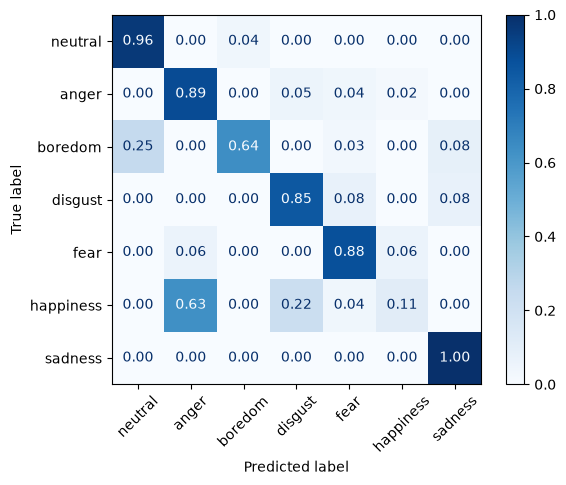

In [19]:
if RUN_FINETUNING:
    import copy
    from transformers import AutoModelForAudioClassification

    name = 'microsoft/wavlm-base-plus'
    extractor = AutoFeatureExtractor.from_pretrained(name)
    model = AutoModelForAudioClassification.from_pretrained(name, num_labels=len(EMOTIONS)).to(DEVICE)
    model.freeze_feature_encoder()

    label = {e: i for i, e in enumerate(EMOTIONS)}
    val_speaker = 13
    fit_rows = train[train.speaker != val_speaker]
    val_rows = train[train.speaker == val_speaker]
    audio = {f: load_audio(f) for f in pd.concat([train, test]).file}
    CROP = 3 * SR

    def batches(rows, batch_size=8, rng=np.random.default_rng(0)):
        rows = rows.sample(frac=1, random_state=int(rng.integers(1e6)))
        for start in range(0, len(rows), batch_size):
            chunk = rows.iloc[start:start + batch_size]
            waves = []
            for f in chunk.file:
                y = audio[f]
                offset = rng.integers(0, max(1, len(y) - CROP))
                waves.append(y[offset:offset + CROP])
            inputs = extractor(waves, sampling_rate=SR, padding=True, return_tensors='pt').to(DEVICE)
            yield inputs, torch.tensor([label[e] for e in chunk.emotion]).to(DEVICE)

    @torch.no_grad()
    def predict(rows):
        model.eval()
        preds = []
        for f in rows.file:
            inputs = extractor(audio[f], sampling_rate=SR, return_tensors='pt').to(DEVICE)
            preds.append(EMOTIONS[model(**inputs).logits.argmax(-1).item()])
        return np.array(preds)

    weights = compute_class_weight('balanced', classes=np.array(EMOTIONS), y=fit_rows.emotion.astype(str))
    loss_fn = nn.CrossEntropyLoss(weight=torch.tensor(weights, dtype=torch.float32).to(DEVICE))
    optimizer = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=3e-5, weight_decay=0.01)

    best_uar, best_state = -1, None
    for epoch in range(10):
        model.train()
        for inputs, target in batches(fit_rows):
            optimizer.zero_grad()
            loss = loss_fn(model(**inputs).logits, target)
            loss.backward()
            optimizer.step()
        val_uar = balanced_accuracy_score(val_rows.emotion.astype(str), predict(val_rows))
        print(f'epoch {epoch}: loss {loss.item():.3f}   validation UAR (speaker {val_speaker}) = {val_uar:.3f}')
        if val_uar > best_uar:
            best_uar, best_state = val_uar, copy.deepcopy({k: v.cpu() for k, v in model.state_dict().items()})

    model.load_state_dict(best_state)
    pred = predict(test)
    results['WavLM fine-tuned'] = {'cv_uar': np.nan, 'cv_std': np.nan, 'test_uar': balanced_accuracy_score(y_test, pred)}
    ConfusionMatrixDisplay.from_predictions(y_test, pred, labels=EMOTIONS, normalize='true', xticks_rotation=45,
                                            values_format='.2f', cmap='Blues')

**Questions** (take-home)
1. Compare the fine-tuned model with the frozen WavLM + linear probe. Is the extra cost worth it here?
2. The validation UAR is computed on one speaker with about 50 utterances. How reliable is early stopping on it, and what would be a more robust protocol?
3. In the PStA you have about 200 speakers, but only one label per speaker. What would you expect from fine-tuning there, and how would you protect yourself against overfitting?

**Solution:**
1. In our run the fine-tuned model is far behind the frozen WavLM layer 5 + logistic regression (between about 0.6 and 0.75 test UAR in our runs, vs. 0.94).
   Fine-tuning 95 million parameters on 255 utterances for 10 epochs is hard: the classifier on top starts from scratch, the mean over the *last* layer is used (the weakest layer for emotion, see Part 3), and early stopping is noisy.
   More epochs, a weighted layer sum (`use_weighted_layer_sum=True` in the model config), different learning rates for head and Transformer, and several runs would help, but each costs GPU time.
   With this little data, a frozen model with a simple classifier is the better cost-benefit trade-off.
2. Not very: one speaker's UAR jumps by several points from epoch to epoch, so the "best" epoch is partly luck.
   More robust: several validation speakers, a fixed number of epochs chosen by cross-validation, or averaging several runs (ensembling).
3. With one label per speaker, the effective number of independent samples is the number of speakers, not of recordings.
   Fine-tuning a model with 95 million parameters on that is very prone to overfitting to speakers and sites.
   Frozen embeddings with a small head, strong regularisation, speaker-independent and leave-one-site-out evaluation, and several seeds are the safer starting point.

# Part 8: Summary (5 min)

In [20]:
summary = pd.DataFrame(results).T.sort_values('cv_uar', ascending=False).round(3)
display(summary)

,cv_uar,cv_std,test_uar
"WavLM layer 5, speaker-normalised",0.949,0.034,0.981
WavLM layer 5 + logistic regression,0.928,0.041,0.941
early fusion: eGeMAPS + WavLM layer 5,0.922,0.034,0.931
WavLM layer 5 + MLP,0.909,0.049,0.901
WavLM all layers + layer-weighted MLP,0.887,0.075,0.913
late fusion: eGeMAPS + WavLM layer 5,0.874,0.053,0.860
WavLM last layer + logistic regression,0.745,0.123,0.848
eGeMAPS + SVM (Lab 02_02),0.629,0.118,0.577
ECAPA + logistic regression,0.624,0.070,0.716
log-mel CNN from scratch,NaN,NaN,0.549


**Questions**
1. Rank the approaches. How well did the cross-validation ranking predict the test ranking?
2. Which system would you have reported as your *one* result, and what is its test UAR?
3. What is the single most important lesson of this lab for working with small clinical speech datasets?

**Solution:**
1. Frozen pre-trained embeddings from a middle layer (with a linear probe, an MLP, a layer-weighted head or fusion) are far ahead of eGeMAPS, ECAPA, the CNN from scratch and our short fine-tuning run.
   At this coarse level the CV ranking predicts the test ranking well.
   Among the top systems the differences are within the spread over speakers, and for weaker systems CV and test can differ by about 0.1 in either direction (eGeMAPS, ECAPA): with 4 test speakers, the test score is uncertain too.
2. The system with the best CV UAR, selected *before* looking at the test column: here the speaker-normalised WavLM layer 5 with logistic regression, test UAR about 0.98.
   Everything else in the test column is for teaching purposes only.
3. Do not train big models from scratch: use pre-trained representations, keep the classifier simple, choose everything by speaker-independent cross-validation, and look at the test set once.

## Final questions
Answer in your own words, two to three sentences each.
1. What is self-supervised learning, and how do wav2vec 2.0, HuBERT and WavLM differ in their pre-training target?
2. What is a probing classifier, and what does a probing curve over the layers tell you?
3. Why are speaker embeddings and SSL embeddings a risk for confounding in clinical datasets, and how do you test for it?
4. What is the difference between early and late fusion, and when would you prefer which?
5. Frozen embeddings + small head vs. fine-tuning: what are the trade-offs?

**Solution:**
1. SSL learns from unlabelled data by solving a pretext task, here: predicting masked parts of the speech signal from their context.
   wav2vec 2.0 identifies the true quantised frame among distractors (contrastive), HuBERT predicts cluster IDs of the masked frames (from k-means on MFCCs or its own features), and WavLM does the same on input that is overlapped with other speakers and noise.
2. A probe is a simple (usually linear) classifier trained on a frozen representation, so it measures how accessible some information is in that representation.
   The curve over layers shows where the model encodes this information, for emotion in the middle layers, between acoustics (bottom) and phonetic content (top).
3. They encode the speaker, gender, age, device and room very well, so a classifier can use these instead of the disease, especially if they are unevenly distributed across classes.
   Test it with speaker- and site-independent evaluation, by probing for the confounders, and by comparing results within subgroups.
4. Early fusion concatenates features and trains one model, late fusion combines the outputs of separate models.
   Early fusion can learn interactions but needs more data and is dominated by large blocks, while late fusion is robust and modular and is the safer choice for small datasets and very different modalities.
5. Frozen embeddings are cheap, stable and need little data, but they cannot adapt to the task.
   Fine-tuning can adapt the whole model and is often best with enough data, but it is expensive, needs a GPU, varies between runs and overfits easily on small datasets.